# 06 — Linear Discriminant Analysis — Bank Marketing Classification

This notebook uses LDA to predict whether a customer will subscribe to a term deposit based on what we know before the call.

## 1. Library imports

In [1]:
# import the libraries for loading data, building the pipeline, and showing plots
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# set the project constants
TARGET_COLUMN = "y"
RANDOM_STATE = 42
MODEL_NAME = "Linear Discriminant Analysis"

# find the project root and make src available
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# import the shared project functions
from src.evaluation import (
    evaluate_binary_classifier,
    results_to_dataframe,
    plot_confusion_matrix,
    plot_roc_curve,
    cross_validate_classifier,
    cross_validation_results_to_dataframe,
)
from src.models import get_candidate_models
from src.preprocessing import build_preprocessor

## 2. Data Loading and Splitting

We use the team's 15 pre-contact predictors and leave out `duration` because the length of the call is only known afterward. The stratified 70/15/15 split keeps about the same share of subscribers in each set.

In [2]:
# read the csv file
df = pd.read_csv(PROJECT_ROOT / "data" / "bank-full.csv", sep=";")

# separate the predictors and encode the target
X = df.drop(columns=[TARGET_COLUMN, "duration"])
y = df[TARGET_COLUMN].map({"yes": 1, "no": 0})

# find the numeric and categorical predictors
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# split the data into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

# split the remaining data into test and validation sets like the other models
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp,
)

# check the split sizes
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (31647, 15)
Validation: (6782, 15)
Testing: (6782, 15)


## 3. Build and Train the LDA Pipeline

The pipeline fits the preprocessing and LDA using the training set. LDA needs the preprocessor to return a dense matrix.

In [3]:
# build the shared preprocessor and make its output dense for lda
preprocessor = build_preprocessor(
    numerical_features, categorical_features, dense_output=True
)

# create the lda model from the project model list
lda_model = get_candidate_models()["lda"]
lda_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", lda_model),
    ]
)

# fit the pipeline using the training data
lda_pipeline.fit(X_train, y_train)
print("LDA model trained.")

LDA model trained.


## 4. Validation Evaluation

In [4]:
# make predictions on the validation set
y_val_pred = lda_pipeline.predict(X_val)

# get the probabilities for the yes class
y_val_prob = lda_pipeline.predict_proba(X_val)[:, 1]

# calculate and show the validation metrics
lda_val_results = evaluate_binary_classifier(
    model_name=MODEL_NAME,
    y_true=y_val,
    y_pred=y_val_pred,
    y_score=y_val_prob,
)
results_to_dataframe([lda_val_results]).round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Linear Discriminant Analysis,0.891,0.5692,0.2799,0.3753,0.764


## 5. Final Test Evaluation

In [5]:
# make predictions on the test set
y_test_pred = lda_pipeline.predict(X_test)

# get the probabilities for the yes class
y_test_prob = lda_pipeline.predict_proba(X_test)[:, 1]

# calculate and show the test metrics
lda_test_results = evaluate_binary_classifier(
    model_name=MODEL_NAME,
    y_true=y_test,
    y_pred=y_test_pred,
    y_score=y_test_prob,
)
results_to_dataframe([lda_test_results]).round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Linear Discriminant Analysis,0.8946,0.598,0.3035,0.4027,0.7661


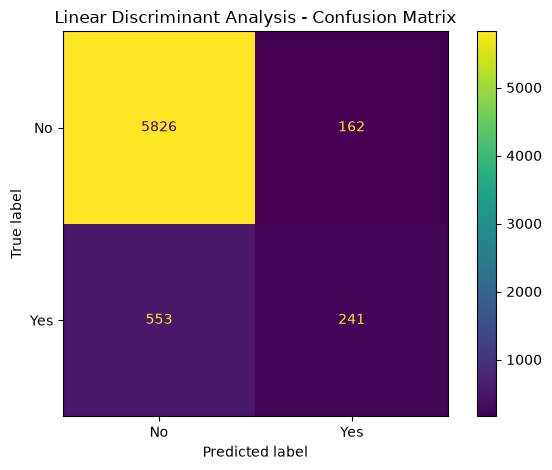

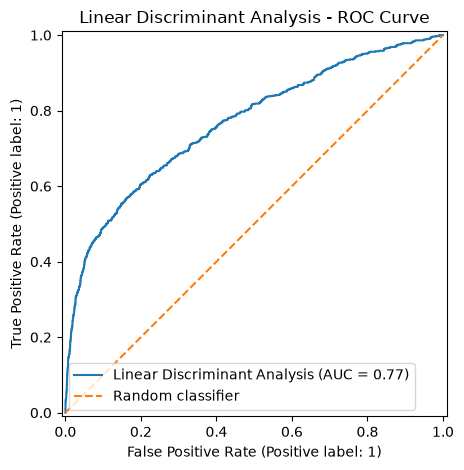

In [6]:
# plot the test confusion matrix
plot_confusion_matrix(y_test, y_test_pred, MODEL_NAME)
plt.show()

# plot the test roc curve
plot_roc_curve(y_test, y_test_prob, MODEL_NAME)
plt.show()

## 6. Stratified 5-Fold Cross-Validation

Each fold fits its own preprocessing and model using only that fold's training rows. The table shows the mean and standard deviation of each metric across the five folds.

In [7]:
# run cross-validation on the training set
lda_cv_results = cross_validate_classifier(
    model_name=MODEL_NAME,
    estimator=lda_pipeline,
    X=X_train,
    y=y_train,
    cv=5,
)

# show the mean and standard deviation for each metric
cross_validation_results_to_dataframe([lda_cv_results]).round(4)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Linear Discriminant Analysis,0.8877,0.0022,0.54,0.0192,0.2701,0.0182,0.3599,0.0197,0.7593,0.0154


## 7. Results Interpretation

On the test set, LDA had 89.46% accuracy and a ROC-AUC of 0.7661. It found 241 of the 794 subscribers and missed 553, giving it 30.35% recall. Since most customers did not subscribe, the high accuracy hides how many subscribers the model misses.

The validation ROC-AUC was 0.7640, and the five training folds averaged 0.7593. The scores are close, so LDA is fairly consistent at ranking potential subscribers. It still misses most subscribers when it makes a yes or no prediction.